In [1]:
# The purpose of this notebook is to pick formulas to make
# The strategy here will be to look at the highest std formulas and
# pick ones far away from each other in feature space.

In [2]:
# import top_uncertain_formulas.csv, stored in top_uncertain_formulas

from pathlib import Path
import pandas as pd

project_root = (
    Path.cwd().resolve().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd().resolve()
)

csv_path = project_root / "predictions" / "top_uncertain_formulas.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Could not find: {csv_path}")

top_uncertain_formulas = pd.read_csv(csv_path)

print(f"Loaded {len(top_uncertain_formulas)} formulas from {csv_path}")
display(top_uncertain_formulas.head())

Loaded 1000 formulas from C:\Users\Brooke\Foam project\predictions\top_uncertain_formulas.csv


,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,std_Avg_Density_g_cm3,pred_24h_avg_pct absorption,std_24h_avg_pct absorption,pred_24h_avg_pct_retention,std_24h_avg_pct_retention,uncertainty_score
0,14.984326,2.312945,1.278052,2.329463,0.000000,0.21456,0.064126,208.244709,131.850282,31.248562,15.401931,0.999118
1,14.982984,1.289218,0.000000,2.774599,1.801093,0.21456,0.064126,212.470625,133.106190,31.248119,15.401931,0.998695
2,14.995737,1.977930,1.004291,2.230660,0.000000,0.21456,0.064126,215.352047,130.998865,31.248599,15.401931,0.998602
3,14.995976,1.556673,0.000000,2.795737,0.000000,0.21456,0.064126,213.009253,133.096516,31.248330,15.401931,0.998540
4,14.998671,1.342379,0.000000,2.412589,1.861044,0.21456,0.064126,216.843765,131.684251,31.248209,15.401931,0.998458


In [3]:
# get a df with TEM, Joncryl, NC513, PEG-DE and NGDE only normalized on a 0-1 scale using mix max scaling

import pandas as pd

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

# Scaling bounds include 0 for extenders so omitted ingredients remain 0.
min_values = pd.Series({
    "TEM": 5.0,
    "Joncryl": 0.0,
    "NC513": 0.0,
    "PEG-DE": 0.0,
    "NGDE": 0.0,
})

max_values = pd.Series({
    "TEM": 15.0,
    "Joncryl": 3.0,
    "NC513": 5.0,
    "PEG-DE": 3.0,
    "NGDE": 3.0,
})

missing_cols = [col for col in formula_cols if col not in top_uncertain_formulas.columns]
if missing_cols:
    raise KeyError(f"Missing formula columns: {missing_cols}")

formulas = top_uncertain_formulas[formula_cols].astype(float)

# Check the values against the stated ingredient limits.
if not formulas["TEM"].between(5.0, 15.0).all():
    raise ValueError("TEM values must be between 5% and 15%.")

for col in ["Joncryl", "PEG-DE", "NGDE"]:
    valid = formulas[col].eq(0) | formulas[col].between(0.7, 3.0)
    if not valid.all():
        raise ValueError(f"{col} must be 0% or between 0.7% and 3%.")

valid_nc513 = formulas["NC513"].eq(0) | formulas["NC513"].between(0.7, 5.0)
if not valid_nc513.all():
    raise ValueError("NC513 must be 0% or between 0.7% and 5%.")

normalized_formulas = (formulas - min_values[formula_cols]) / (
    max_values[formula_cols] - min_values[formula_cols]
)

display(normalized_formulas)

,TEM,Joncryl,NC513,PEG-DE,NGDE
0,0.998433,0.770982,0.255610,0.776488,0.000000
1,0.998298,0.429739,0.000000,0.924866,0.600364
2,0.999574,0.659310,0.200858,0.743553,0.000000
3,0.999598,0.518891,0.000000,0.931912,0.000000
4,0.999867,0.447460,0.000000,0.804196,0.620348
...,...,...,...,...,...
995,0.989061,0.306790,0.418672,0.548076,0.000000
996,0.994735,0.244463,0.330312,0.263236,0.416571
997,0.985497,0.566569,0.000000,0.331569,0.911596
998,0.998009,0.234529,0.000000,0.000000,0.000000


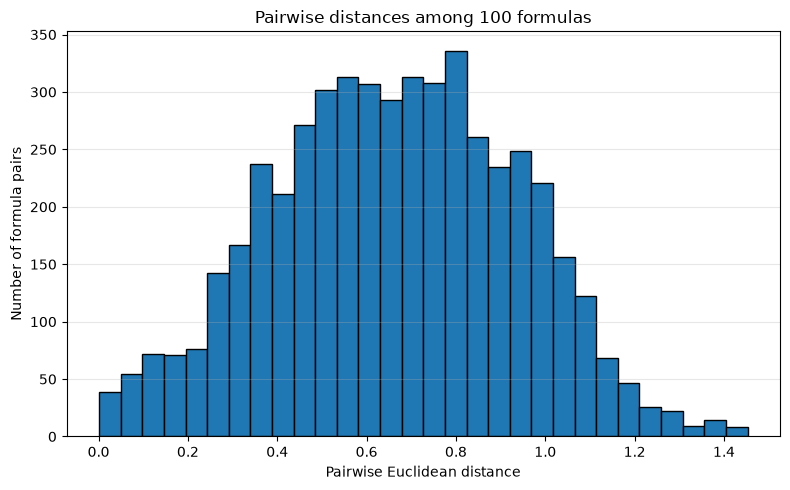

In [4]:
# compute pairwise euclidean distances between the first 100 formulas in normalized_formulas and plot histogram

import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

formulas_first_100 = normalized_formulas.iloc[:100]

distances = pdist(formulas_first_100.to_numpy(dtype=float), metric="euclidean")

plt.figure(figsize=(8, 5))
plt.hist(distances, bins=30, edgecolor="black")
plt.xlabel("Pairwise Euclidean distance")
plt.ylabel("Number of formula pairs")
plt.title(f"Pairwise distances among {len(formulas_first_100)} formulas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# compute the pairwise distance between the first 100 formulas and the training data 
# just out of curiosity wondering if they will be far

In [6]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)


# Show the 25 original formulas and their three measured targets from df.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
df = df[formula_cols + measured_target_cols].copy()
df[formula_cols] = df[formula_cols].fillna(0.0)
df[measured_target_cols] = df[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

assert len(df) == 25, (
    f"Expected the 25 original samples; found {len(df)}."
)
display(df)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
0,8,0.0,0.0,0.0,0.0,0.192000,113.616943,31.770000
1,8,0.7,0.0,0.0,0.0,0.195000,103.817309,33.120000
2,8,1.0,0.0,0.0,0.0,0.159000,129.464292,36.250000
3,8,1.5,0.0,0.0,0.0,0.159933,120.749405,25.330000
4,8,2.0,0.0,0.0,0.0,0.201000,113.871581,26.580000
5,8,3.0,0.0,0.0,0.0,0.202000,111.044347,27.400000
6,5,0.0,0.0,0.0,0.0,0.298930,56.958538,36.614852
7,5,0.0,0.7,0.0,0.0,0.360035,57.115160,44.587460
8,5,0.0,1.0,0.0,0.0,0.355557,44.308895,43.766577
9,5,0.0,2.0,0.0,0.0,0.358055,43.326301,44.186536


Number of cross-group distances: 2,500


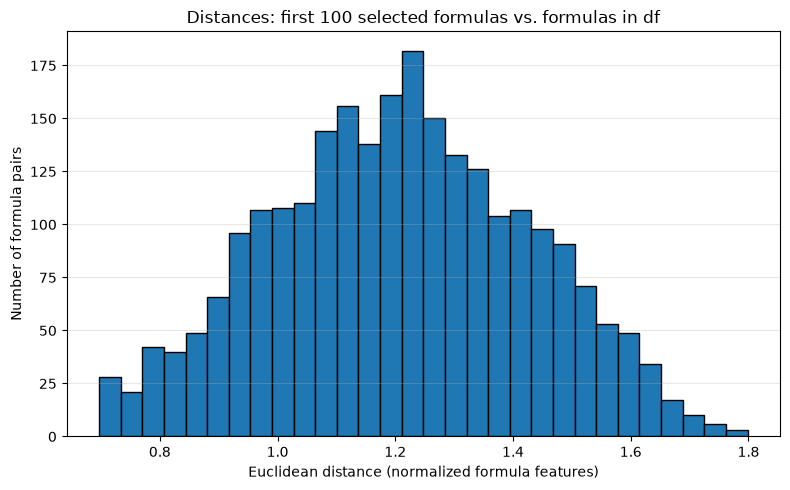

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

# Scale both groups with the same bounds.
min_values = pd.Series({
    "TEM": 5.0,
    "Joncryl": 0.0,
    "NC513": 0.0,
    "PEG-DE": 0.0,
    "NGDE": 0.0,
})
max_values = pd.Series({
    "TEM": 15.0,
    "Joncryl": 3.0,
    "NC513": 5.0,
    "PEG-DE": 3.0,
    "NGDE": 3.0,
})

df_formulas = df[formula_cols].astype(float)
df_normalized = (df_formulas - min_values[formula_cols]) / (
    max_values[formula_cols] - min_values[formula_cols]
)

# Keep only rows with complete formula values.
df_normalized = df_normalized.dropna()
selected_normalized = formulas_first_100[formula_cols].dropna()

# Each row is a distance between one selected formula and one formula in df.
distance_matrix = cdist(
    selected_normalized.to_numpy(),
    df_normalized.to_numpy(),
    metric="euclidean",
)
distances = distance_matrix.ravel()

print(f"Number of cross-group distances: {len(distances):,}")

plt.figure(figsize=(8, 5))
plt.hist(distances, bins=30, edgecolor="black")
plt.xlabel("Euclidean distance (normalized formula features)")
plt.ylabel("Number of formula pairs")
plt.title("Distances: first 100 selected formulas vs. formulas in df")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# look at the formulas from the training data and some of highest std to see 

# Find the closest pair across the two groups.
selected_pos, df_pos = np.unravel_index(
    np.argmin(distance_matrix),
    distance_matrix.shape,
)

closest_distance = distance_matrix[selected_pos, df_pos]

print(f"Closest distance: {closest_distance:.6f}")
print("\nClosest formula from selected_normalized:")
display(selected_normalized.iloc[[selected_pos]])

print("\nClosest formula from df_normalized:")
display(df_normalized.iloc[[df_pos]])

Closest distance: 0.696704

Closest formula from selected_normalized:


,TEM,Joncryl,NC513,PEG-DE,NGDE
62,0.996593,0.0,0.0,0.987536,0.0



Closest formula from df_normalized:


,TEM,Joncryl,NC513,PEG-DE,NGDE
20,0.3,0.0,0.0,1.0,0.0


In [9]:
# select formulas to make that are furthest from the training data and other selected candidates 

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

# Use the same bounds used to create df_normalized.
min_values = np.array([5.0, 0.0, 0.0, 0.0, 0.0])
max_values = np.array([15.0, 3.0, 5.0, 3.0, 3.0])

# Normalize candidates with the same scaling as df_normalized.
candidate_formulas = top_uncertain_formulas[formula_cols].astype(float)
candidate_normalized = (
    candidate_formulas.to_numpy() - min_values
) / (max_values - min_values)

# Ensure the reference formulas are in the same feature order and are finite.
reference_normalized = df_normalized[formula_cols].to_numpy(dtype=float)

if not np.isfinite(candidate_normalized).all():
    raise ValueError("Candidate formulas contain missing or non-finite values.")
if not np.isfinite(reference_normalized).all():
    raise ValueError("df_normalized contains missing or non-finite values.")

n_select = min(15, len(top_uncertain_formulas))
if n_select == 0:
    raise ValueError("top_uncertain_formulas contains no formulas.")
if len(reference_normalized) == 0:
    raise ValueError("df_normalized contains no reference formulas.")

# For each candidate, its distance to its nearest formula in the reference set.
nearest_distance = cdist(
    candidate_normalized,
    reference_normalized,
    metric="euclidean",
).min(axis=1)

selected_positions = []
selected_nearest_distances = []
is_selected = np.zeros(len(candidate_normalized), dtype=bool)

for _ in range(n_select):
    # Pick the remaining candidate with the largest nearest-neighbor distance.
    scores = nearest_distance.copy()
    scores[is_selected] = -np.inf
    chosen_position = int(np.argmax(scores))

    selected_positions.append(chosen_position)
    selected_nearest_distances.append(nearest_distance[chosen_position])
    is_selected[chosen_position] = True

    # Update each remaining candidate's nearest distance to include this selection.
    distance_to_chosen = cdist(
        candidate_normalized,
        candidate_normalized[[chosen_position]],
        metric="euclidean",
    ).ravel()
    nearest_distance = np.minimum(nearest_distance, distance_to_chosen)

# Keep the selected formulas and their selection order/distance.
selected_list = top_uncertain_formulas.iloc[selected_positions].copy()
selected_list.insert(0, "selection_order", range(1, n_select + 1))
selected_list["distance_to_nearest_existing_or_selected"] = (
    selected_nearest_distances
)

display(selected_list)

,selection_order,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,std_Avg_Density_g_cm3,pred_24h_avg_pct absorption,std_24h_avg_pct absorption,pred_24h_avg_pct_retention,std_24h_avg_pct_retention,uncertainty_score,distance_to_nearest_existing_or_selected
363,1,14.888160,0.000000,0.000000,2.908004,2.905165,0.21456,0.064126,226.263251,133.172426,31.245636,15.401931,0.991770,1.188774
765,2,14.830395,2.930495,0.000000,0.000000,2.913217,0.21456,0.064126,158.412545,123.816496,31.247779,15.401931,0.988645,1.187460
721,3,14.928577,0.000000,3.959476,0.000000,1.994655,0.21456,0.064126,181.224228,121.997114,31.248666,15.401931,0.988925,1.034437
251,4,14.826522,2.898642,0.000000,2.844956,0.000000,0.21456,0.064126,191.106872,134.093431,31.248371,15.401931,0.992997,0.972563
262,5,14.893340,2.697412,3.165824,0.000000,0.000000,0.21456,0.064126,176.752513,123.248468,31.248255,15.401931,0.992848,0.941410
234,6,14.974863,1.160449,1.237985,1.507367,0.977719,0.21456,0.064126,230.213875,126.512228,31.248390,15.401931,0.993225,0.826941
826,7,14.821453,0.000000,4.996603,0.934102,0.000000,0.21456,0.064126,242.500876,121.947092,31.249052,15.401931,0.988210,0.762995
539,8,14.992825,0.000000,0.000000,0.709276,2.499169,0.21456,0.064126,216.721395,123.595069,31.247053,15.401931,0.990192,0.734103
91,9,14.950077,0.000000,2.611559,2.831297,0.000000,0.21456,0.064126,236.732530,131.956400,31.247980,15.401931,0.995603,0.725307
541,10,14.985823,0.000000,1.708910,0.000000,0.000000,0.21456,0.064126,193.689780,122.749065,31.247810,15.401931,0.990155,0.719149


Number of formula pairs: 105


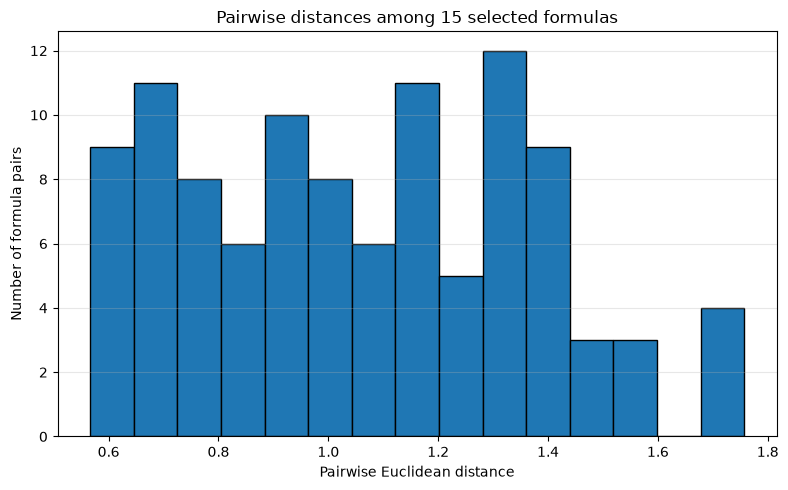

In [10]:
# plot histogram of pairwise distances in selected_list

import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

# Normalize using the same bounds as df_normalized.
min_values = [5.0, 0.0, 0.0, 0.0, 0.0]
max_values = [15.0, 3.0, 5.0, 3.0, 3.0]

selected_normalized = (
    selected_list[formula_cols].astype(float) - min_values
) / (
    [hi - lo for lo, hi in zip(min_values, max_values)]
)

pairwise_distances = pdist(
    selected_normalized.to_numpy(),
    metric="euclidean",
)

print(f"Number of formula pairs: {len(pairwise_distances)}")

plt.figure(figsize=(8, 5))
plt.hist(pairwise_distances, bins=15, edgecolor="black")
plt.xlabel("Pairwise Euclidean distance")
plt.ylabel("Number of formula pairs")
plt.title(f"Pairwise distances among {len(selected_list)} selected formulas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Number of distances: 375


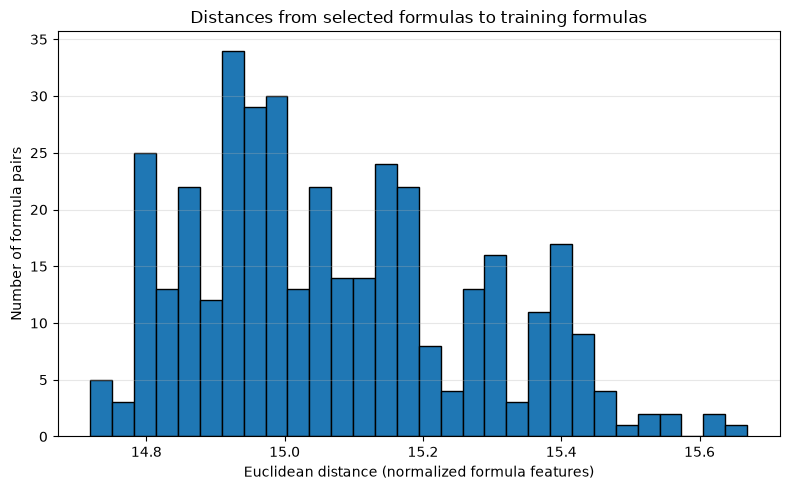

In [11]:
# plot of selected_formulas and the training data distances 

import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.distance import cdist

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

selected_values = selected_list[formula_cols].to_numpy(dtype=float)
training_values = df_normalized[formula_cols].to_numpy(dtype=float)

if not np.isfinite(selected_values).all() or not np.isfinite(training_values).all():
    raise ValueError("Formula data contains missing or non-finite values.")

# Each selected formula is compared with every training formula.
distance_matrix = cdist(selected_values, training_values, metric="euclidean")
distances = distance_matrix.ravel()

print(f"Number of distances: {len(distances):,}")

plt.figure(figsize=(8, 5))
plt.hist(distances, bins=30, edgecolor="black")
plt.xlabel("Euclidean distance (normalized formula features)")
plt.ylabel("Number of formula pairs")
plt.title("Distances from selected formulas to training formulas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

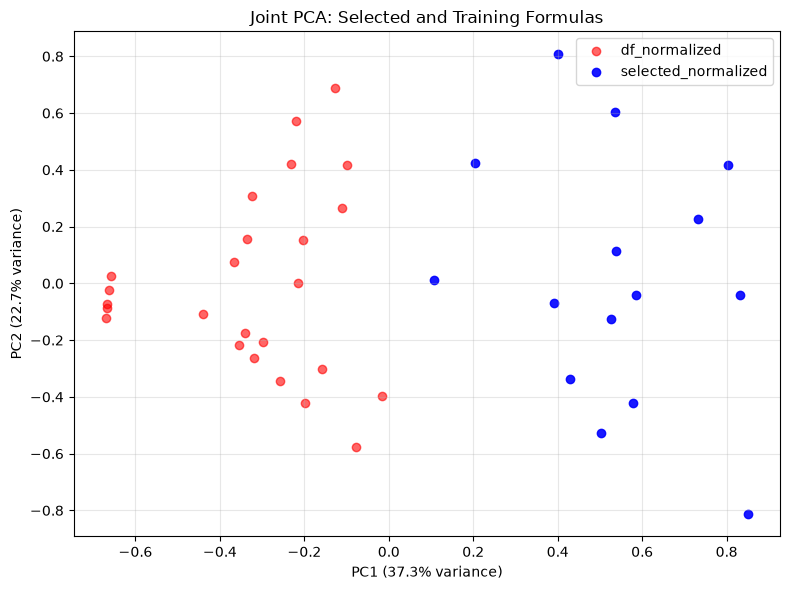

In [ ]:
# PCA plot of the selected formulas and the training data

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

training_values = df_normalized[formula_cols].to_numpy(dtype=float)
selected_values = selected_normalized[formula_cols].to_numpy(dtype=float)

if not np.isfinite(training_values).all() or not np.isfinite(selected_values).all():
    raise ValueError("Formula data contains missing or non-finite values.")

# Combine both sets before fitting PCA
all_values = np.vstack([training_values, selected_values])

if min(all_values.shape) < 2:
    raise ValueError("PCA with two components needs at least 2 rows and 2 formula columns.")

pca = PCA(n_components=2)
all_pcs = pca.fit_transform(all_values)

# Split the joint PCA coordinates back into the two sets
n_training = len(training_values)
training_pcs = all_pcs[:n_training]
selected_pcs = all_pcs[n_training:]

plt.figure(figsize=(8, 6))
plt.scatter(
    training_pcs[:, 0], training_pcs[:, 1],
    color="red", alpha=0.6, label="df_normalized"
)
plt.scatter(
    selected_pcs[:, 0], selected_pcs[:, 1],
    color="blue", alpha=0.9, label="selected_normalized"
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Joint PCA: Selected and Training Formulas")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()